# What habit-app users complain about, and what they ask for

Using **3,670 Google Play reviews** of three gamified habit apps, this notebook asks:

1. **Can off-the-shelf sentiment models find unhappy users?** I score VADER and TextBlob against the reviewer's own star rating instead of judging them by eye.
2. **Can a local LLM label what a review is *about* reliably?** I benchmark `qwen3:14b` against 200 reviews I labelled by hand.
3. **What do users of the target app complain about and ask for, and how does that compare with its competitors?**

The target app is **Life Reset** (`build.designand.riselife`). It is compared with **Kaizen AI** and **Habitica**, using reviews posted since October 2024 so that all three apps cover the same period.

Data snapshot: `data/raw/reviews.csv`, with LLM labels in `data/processed/llm_labels.csv`. Re-scraping with `python -m reviewinsights.scrape` will change the numbers below.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

import pandas as pd
from IPython.display import display

from reviewinsights.config import RAW_REVIEWS, APPS, TARGET_APP, FIGURES, LLM_LABELS, HUMAN_LABELS, LLM_MODEL
from reviewinsights import preprocess as pp, sentiment as sa, topics, plots, benchmark as bm
from reviewinsights.llm import INTENTS

pd.set_option("display.max_colwidth", 160)
plots.apply_style()
pp.ensure_nltk_data()
TARGET = APPS[TARGET_APP]

## 1. The data

In [2]:
df = pd.read_csv(RAW_REVIEWS, parse_dates=["posted_at"])
df = df[df["text"].notna()].reset_index(drop=True)
df["name"] = df["app"].map(APPS)

overview = df.groupby("name").agg(
    reviews=("rating", "size"),
    avg_stars=("rating", "mean"),
    share_1_2_stars=("rating", lambda r: (r <= 2).mean()),
    median_words=("text", lambda t: t.str.split().str.len().median()),
    first=("posted_at", "min"),
    last=("posted_at", "max"),
).sort_values("reviews", ascending=False)
overview.style.format({"avg_stars": "{:.2f}", "share_1_2_stars": "{:.0%}", "median_words": "{:.0f}",
                       "first": "{:%Y-%m}", "last": "{:%Y-%m}", "reviews": "{:,}"})

,reviews,avg_stars,share_1_2_stars,median_words,first,last
name,,,,,,
Habitica,"2,021",4.21,13%,17,2024-10,2026-11
Life Reset,"1,176",3.33,38%,6,2024-10,2026-11
Kaizen AI,473,4.18,16%,3,2025-08,2026-10


In [3]:
pd.crosstab(df["posted_at"].dt.to_period("Q"), df["name"]).rename_axis(index="quarter", columns=None)

,Habitica,Kaizen AI,Life Reset
quarter,,,
2024Q4,453,0,90
2025Q1,374,0,30
2025Q2,263,0,17
2025Q3,234,1,12
2025Q4,179,34,42
2026Q1,167,408,143
2026Q2,124,19,106
2026Q3,163,10,405
2026Q4,64,1,331


The three apps are very different populations:
- **Life Reset** has the most complaints: 38% of its reviews are 1–2★, against 13–16% for the others. Most of its reviews (736 of 1,176) arrived from July 2026 onwards.
- **Habitica** is an established app. Its reviews are the longest (median 17 words) and spread evenly over time.
- **Kaizen AI** got 408 of its 473 reviews in early 2026, and most are a few words long (median 3), so it says less per review.

## 2. Can lexicon models find unhappy users?

VADER and TextBlob are popular because they need no training data. The star rating gives a free ground truth: **1–2★ = negative, 4–5★ = positive**, and 3★ is left out of the binary metrics.

I run both on the raw text and on text passed through a common "clean everything first" step (punctuation, emoji, case and stopwords removed). That step was in the first version of this project, and I want to measure what it costs.

In [4]:
df["legacy_text"] = df["text"].map(pp.legacy_clean)
for model, fn in [("VADER", sa.vader_score), ("TextBlob", sa.textblob_score)]:
    df[f"{model} raw"] = df["text"].map(fn)
    df[f"{model} cleaned"] = df["legacy_text"].map(fn)

score_cols = ["VADER raw", "VADER cleaned", "TextBlob raw", "TextBlob cleaned"]
results = pd.DataFrame({c: sa.evaluate(df[c], df["rating"]) for c in score_cols}).T
results.style.format("{:.3f}").highlight_max(color="#cde2fb")

,spearman,balanced_accuracy,pos_recall,neg_recall
VADER raw,0.449,0.650,0.854,0.447
VADER cleaned,0.372,0.603,0.855,0.352
TextBlob raw,0.461,0.547,0.811,0.283
TextBlob cleaned,0.415,0.516,0.788,0.243


In [5]:
flipped = df[(df["rating"] <= 2) & (df["VADER raw"] <= -0.05) & (df["VADER cleaned"] >= 0.05)]
print(f"{len(flipped):,} negative reviews turn positive after cleaning\n")
flipped.loc[flipped["text"].str.len().between(25, 70), ["text", "legacy_text", "VADER raw", "VADER cleaned"]].head(5).round(2)

88 negative reviews turn positive after cleaning



,text,legacy_text,VADER raw,VADER cleaned
124,"no free version, no trial period",free version trial period,-0.60,0.51
162,why this app want money 😭💰,app want money,-0.42,0.08
190,not even a free trial?? don't install guys!,even free trial dont install guy,-0.52,0.51
747,not paying for this as its not worth paying for.,paying worth paying,-0.17,0.23
754,"couldn't even start using the app, its just not free",couldnt even start using app free,-0.40,0.51


**Findings**
- **Cleaning the text first hurts both models.** VADER's negative recall falls from 45% to 35%, because NLTK's stopword list contains *not*, *no* and *nor*: *"no free version, no trial period"* becomes *"free version trial period"*, which scores as positive.
- **On raw text VADER beats TextBlob at finding complaints** (45% vs 28% negative recall).
- **Both still miss most complaints.** Many 1★ reviews state a fact without emotional words (*"you can't use it at all for free"*), and a lexicon has nothing to score.

## 3. Can topic modelling say what the complaints are about?

LDA on the 1–2★ reviews of all three apps, with lemmatised tokens, merged word pairs (`free_trial`) and the number of topics chosen by c_v coherence.

In [6]:
complaints = df[df["rating"] <= 2].reset_index(drop=True)
tm = topics.fit([pp.tokens_for_topics(t) for t in complaints["text"]], k_values=range(3, 9))
print("c_v coherence by k:", {k: round(v, 3) for k, v in tm.coherence_by_k.items()}, "→ k =", tm.k)
tm.top_words(10)

c_v coherence by k: {3: np.float64(0.265), 4: np.float64(0.304), 5: np.float64(0.269), 6: np.float64(0.263), 7: np.float64(0.268), 8: np.float64(0.284)} → k = 4


,words
topic,
0,"even, free, question, pay, work, try, paywall, task, start, make"
1,"make, task, pay, free, game, paid, time, even, money, work"
2,"subscription, pay, way, even, idea, task, good, need, month, without"
3,"error, server, working, time, day, subscription, program, tried, fix, paid"


**It can't, on this data.** The best model scores a coherence of only 0.30, and *pay*, *free* and *subscription* appear in nearly every topic, so billing complaints can't be told apart from bug reports. The reviews are short and the vocabulary is shared across problems. This is the gap the LLM classifier below is meant to fill.

## 4. An LLM intent classifier, and how far to trust it

Every review is labelled by `qwen3:14b`, running locally through [Ollama](https://ollama.com), with one **intent** (bug, pricing, feature_request, usability, praise, other) and one **sentiment**. Output is forced into a JSON schema and the temperature is 0, so results are repeatable (`src/reviewinsights/llm.py`).

**How it was evaluated.** I labelled 200 reviews by hand, using a written guide (`data/labels/README.md`) and the same definitions and tie-break rule the model gets. The sample is balanced across star ratings, and I labelled it with star ratings and model output hidden. As a reference point, a **second annotator** labelled the same 200 reviews blind from the same guide. That annotator was Claude, an AI assistant, so it measures agreement between careful readers of the guide, not between two humans.

In [7]:
llm = pd.read_csv(LLM_LABELS)[["review_id", "intent", "sentiment"]].rename(columns={"sentiment": "llm_sentiment"})
df = df.merge(llm, on="review_id", how="left")
print(f"{df['intent'].notna().sum():,} of {len(df):,} reviews classified by {LLM_MODEL}")

human = pd.read_csv(HUMAN_LABELS)
second = pd.read_csv(bm.SECOND_ANNOTATOR).rename(columns={"intent": "second"})
bench = (human.merge(df[["review_id", "intent"]].rename(columns={"intent": "llm"}), on="review_id")
              .merge(second, on="review_id"))
assert bench["intent"].isin(INTENTS).all() and len(bench) == len(human)

def row(pred):
    hits = (bench["intent"] == pred).to_numpy(dtype=float)
    lo, hi = sa.bootstrap_ci(hits)
    return {"accuracy": hits.mean(), "95% CI": f"{lo:.0%}–{hi:.0%}", "Cohen's kappa": bm.cohen_kappa(bench["intent"], pred)}

majority = bench["intent"].value_counts().index[0]
summary = pd.DataFrame({
    f"LLM ({LLM_MODEL})": row(bench["llm"]),
    "second annotator": row(bench["second"]),
    f"always '{majority}'": row(pd.Series(majority, index=bench.index)),
}).T
print(f"{len(bench)} hand-labelled reviews")
summary.style.format({"accuracy": "{:.1%}", "Cohen's kappa": "{:.2f}"})

3,670 of 3,670 reviews classified by qwen3:14b
200 hand-labelled reviews


,accuracy,95% CI,Cohen's kappa
LLM (qwen3:14b),80.0%,74%–86%,0.75
second annotator,83.5%,78%–88%,0.79
always 'praise',34.0%,28%–41%,0.00


In [8]:
report = bm.intent_report(bench["intent"], bench["llm"])
report["f1 (second annotator)"] = bm.intent_report(bench["intent"], bench["second"])["f1"]
report.style.format({"precision": "{:.2f}", "recall": "{:.2f}", "f1": "{:.2f}",
                     "f1 (second annotator)": "{:.2f}", "support": "{:.0f}"})

,precision,recall,f1,support,f1 (second annotator)
bug,0.83,0.95,0.89,37,0.92
pricing,0.91,0.93,0.92,45,0.90
feature_request,0.70,0.78,0.74,18,0.89
usability,0.55,0.35,0.43,17,0.38
praise,0.98,0.79,0.88,68,0.90
other,0.35,0.60,0.44,15,0.41


In [9]:
pd.crosstab(bench["intent"], bench["llm"], rownames=["human"], colnames=["LLM"]) \
  .reindex(index=list(INTENTS), columns=list(INTENTS), fill_value=0)

LLM,bug,pricing,feature_request,usability,praise,other
human,,,,,,
bug,35,0,0,1,0,1
pricing,0,42,0,0,0,3
feature_request,1,0,14,3,0,0
usability,4,1,5,6,0,1
praise,0,1,1,0,54,12
other,2,2,0,1,1,9


**Findings**
- **The LLM agrees with my labels 80% of the time** (95% CI 75–86%, Cohen's κ = 0.75). Always guessing the most common label would score 34%. The second annotator scores 84% (κ = 0.79), so the local model is close to the level of agreement the guide itself allows.
- **It is reliable on the labels a product team acts on.** Bug F1 is 0.89 (it finds 35 of 37 bug reports), pricing 0.92, praise 0.88.
- **It is weak on *usability* and *other*, and so was the second annotator.** Usability F1 is 0.43 for the model and 0.38 for the second annotator. The line between "annoying design" and "broken" or "please change it" is fuzzy in the guide itself, so the next step is to tighten the definitions, not to swap the model.
- **Most other disagreements are short, vague, positive reviews** like *"so far, so good"*, which I called praise and the model called other:

In [10]:
# Where the LLM and the human disagree: mostly borderline cases.
bench[bench["intent"] != bench["llm"]].loc[lambda d: d["text"].str.len() < 160, ["text", "intent", "llm"]] \
     .rename(columns={"intent": "human"}).head(8)

,text,human,llm
2,Let's Try. It's my first day. Will review later.,praise,other
4,wait for result,praise,other
14,let's start the game,praise,other
21,I feel like I can be back in track,praise,other
28,i am a new user of this app. I am start a new journey through this application,praise,other
30,yess we don't have to pay❤️🙏,praise,pricing
61,"so far, so good",praise,other
69,I can't singin this app can someone help me,bug,other


The model also returns a sentiment for each review, so it can be scored against star ratings in the same way as VADER and TextBlob:

,spearman,balanced_accuracy,pos_recall,neg_recall
TextBlob,0.461,0.547,0.811,0.283
VADER,0.449,0.650,0.854,0.447
LLM (qwen3:14b),0.769,0.858,0.787,0.929


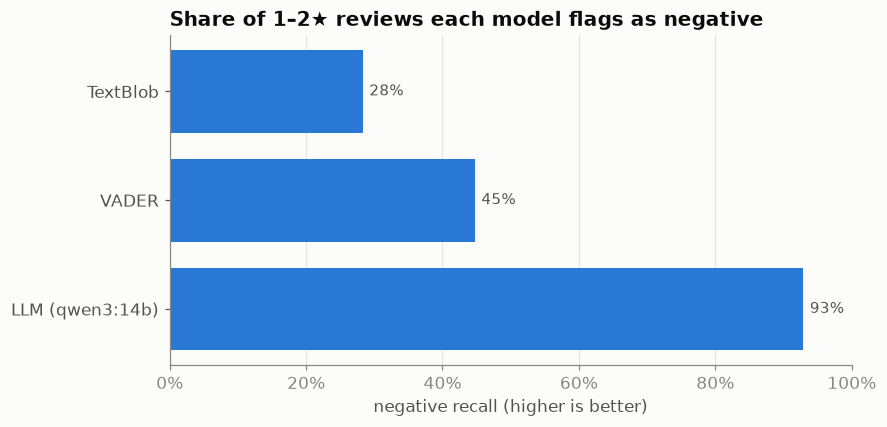

In [11]:
df["LLM"] = df["llm_sentiment"].map({"negative": -1, "neutral": 0, "positive": 1})
rated = df.dropna(subset=["LLM"])
compare = pd.DataFrame({m: sa.evaluate(rated[c], rated["rating"])
                        for m, c in [("TextBlob", "TextBlob raw"), ("VADER", "VADER raw"), (f"LLM ({LLM_MODEL})", "LLM")]}).T
display(compare.style.format("{:.3f}").highlight_max(color="#cde2fb"))

fig, ax = plots.grouped_hbar(compare[["neg_recall"]], "Share of 1–2★ reviews each model flags as negative",
                             "negative recall (higher is better)")
plots.save(fig, "negative_recall", FIGURES)

**The LLM finds 93% of 1–2★ reviews, against 45% for VADER.** Its rank correlation with the stars is 0.77 (VADER 0.45). It is a little worse on positive reviews (79% vs 85%), because it calls many one-word reviews like *"good"* neutral.

## 5. What do unhappy users complain about?

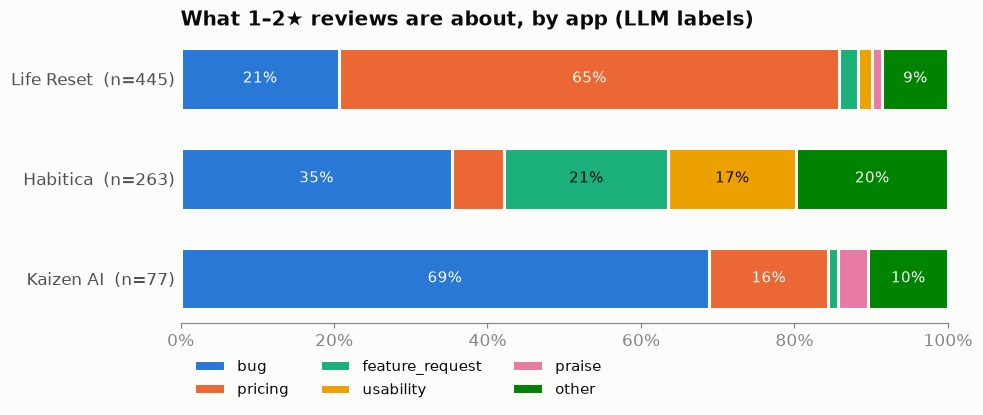

In [12]:
labelled = df.dropna(subset=["intent"])
low = labelled[labelled["rating"] <= 2]
order = [i for i in INTENTS if i in set(low["intent"])]
share = pd.crosstab(low["name"], low["intent"], normalize="index")[order]
counts = low["name"].value_counts()
share = share.loc[counts.index]
fig, ax = plots.stacked_share(share, "What 1–2★ reviews are about, by app (LLM labels)", counts)
plots.save(fig, "complaint_intents", FIGURES)

In [13]:
# All ratings, not just complaints
pd.crosstab(labelled["name"], labelled["intent"], normalize="index")[list(INTENTS)] \
  .style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

intent,bug,pricing,feature_request,usability,praise,other
name,,,,,,
Habitica,9%,2%,21%,5%,49%,13%
Kaizen AI,14%,4%,1%,0%,49%,32%
Life Reset,10%,28%,3%,1%,34%,24%


**Findings**
- **Life Reset's problem is the paywall.** 65% of its 1–2★ reviews are about pricing, against under 10% for Habitica and 16% for Kaizen AI.
- **Kaizen AI's complaints are mostly bugs** (69%), but they rest on only 77 reviews.
- **Habitica's complaints are spread out:** bugs 35%, feature requests 21%, usability 17%. That is the profile of a mature app whose users want it to change, not one that fails at the door.

## 6. Life Reset in detail

**Did the paywall complaints go away?** Life Reset's average rating jumped in July 2026, so the obvious question is whether something was fixed.

In [14]:
lr = labelled[labelled["name"] == TARGET].copy()
monthly = lr[lr["posted_at"] >= "2026-01-01"].groupby(lr["posted_at"].dt.to_period("M")).agg(
    reviews=("rating", "size"),
    avg_stars=("rating", "mean"),
    median_words=("text", lambda t: t.str.split().str.len().median()),
    main_version=("app_version", lambda v: v.mode().iloc[0] if v.notna().any() else ""),
).rename_axis("month")
display(monthly.style.format({"avg_stars": "{:.2f}", "median_words": "{:.0f}"}))

lr["period"] = lr["posted_at"].lt("2026-07-01").map({True: "before Jul 2026", False: "from Jul 2026"})
lr_low = lr[lr["rating"] <= 2]
pd.crosstab(lr_low["period"], lr_low["intent"], normalize="index")[list(INTENTS)] \
  .assign(n=lr_low["period"].value_counts()).style.format("{:.0%}").format("{:,}", subset="n")

,reviews,avg_stars,median_words,main_version
month,,,,
2026-01,68,2.24,16,5.0.3
2026-02,33,2.24,18,5.0.12
2026-03,42,1.64,18,5.0.24
2026-04,41,1.51,17,5.1.1
2026-05,40,1.75,24,5.1.10
2026-06,25,2.04,11,6.2.0
2026-07,85,4.20,2,6.2.3
2026-08,182,4.15,3,6.4.6
2026-09,138,3.80,4,6.5.2


intent,bug,pricing,feature_request,usability,praise,other,n
period,,,,,,,
before Jul 2026,23%,67%,3%,2%,0%,6%,295
from Jul 2026,16%,62%,2%,2%,4%,14%,150


**No, the paywall complaint is still there.** From July 2026 (version 6.2 onwards) the average rating rose from under 2★ (March–May) to about 4★, and review volume rose sharply. But the median review shrank from 17–24 words to 2–5, and among the remaining 1–2★ reviews, pricing is still 62% of complaints (67% before). The higher rating comes from many more short positive reviews, not from fewer people hitting the paywall. Pricing complaints also get **80% of all thumbs-up** on Life Reset's 1–2★ reviews, so other users agree with them.

In [15]:
thumbs = lr_low.groupby("intent")["thumbs_up"].sum()
print(f"Share of all thumbs-up on {TARGET} 1–2★ reviews: " +
      ", ".join(f"{k} {v:.0%}" for k, v in (thumbs / thumbs.sum()).sort_values(ascending=False).items()))

Share of all thumbs-up on Life Reset 1–2★ reviews: pricing 80%, bug 14%, feature_request 3%, usability 1%, other 1%, praise 0%


In [16]:
target = labelled[labelled["name"] == TARGET]
bugs = target[target["intent"] == "bug"]
print(f"{len(bugs)} {TARGET} bug reports. Most-liked:")
bugs.nlargest(8, "thumbs_up")[["rating", "thumbs_up", "app_version", "text"]]

118 Life Reset bug reports. Most-liked:


,rating,thumbs_up,app_version,text
673,2,37,6.2.3,"I've been using this app since January and was really hopeful. But the more I use it, the more bugs I encounter. It could be because I use Android, but most..."
474,1,24,6.5.0,It's like the app was created using AI and then hastily finished; it's full of bugs and the features are mostly unusable. like when you add a new task you c...
988,1,21,5.0.0,"I made it to the vow, signed my name and didnt see a button to continue. I ended up having to restart the quiz and then couldn't make it past the Get My Pro..."
1100,5,19,2.1.25,I cant even access it cus it says theres something wrong with my credential and I cant seem to find the solution anywhere. Please help me. I will change thi...
1011,1,16,4.4.7,using the back button completely resets the 10+ minute account setup process. the app seems to be a good idea but it feels very beta the way display element...
1158,1,16,2.1.6,I can't go past the sign up screen a bug shows up showing error in the code. Poorly built app would give it 0 stars if possible
859,3,15,5.0.23,Wanna commit to using this app but there are quite a few bugs. 1. If I complete tasks for the previous day streak gains are added to current day 2. Ranked d...
922,2,15,5.0.10,"The app is useful when working, the problem is it rarely works. Screens get stuck,and if you add too many tasks to a list the app fails to function. I have ..."


In [17]:
requests = target[target["intent"] == "feature_request"]
old_filter = target[(target["rating"] >= 4) & (target["VADER raw"] <= -0.3)]
print(f"LLM: {len(requests)} feature requests. Old VADER filter (≥4★ but negative text): {len(old_filter)} reviews, "
      f"{old_filter['review_id'].isin(requests['review_id']).sum()} of them requests.\n")
print("Feature requests by star rating:", requests["rating"].value_counts().sort_index().to_dict())
requests.sort_values("thumbs_up", ascending=False)[["rating", "thumbs_up", "text"]]

LLM: 35 feature requests. Old VADER filter (≥4★ but negative text): 3 reviews, 0 of them requests.

Feature requests by star rating: {1: 5, 2: 6, 3: 6, 4: 13, 5: 5}


,rating,thumbs_up,text
1059,2,22,I like the concept of the app but if you work night shift it won't work for you. Wake up times are restricted to just a few hours after dawn. I don't get ho...
996,2,21,"Literally talked about how I need an app like this to make it a game and level up. Sadly this dosent deliver. You get quizzed at the start, which would take..."
1055,2,9,"Great idea but needs work. Currently no customisation of tasks/goals, you're stuck with the ones it gives you based on a survey it asks you. It intentionall..."
976,4,8,"I like this app really great for commitment even if a little expensive. Maybe they should also make it a little more women powered too, that would broaden t..."
1072,3,7,The idea of the app is great and something I can see positively effecting me. The downside is no customisation to the schedule which comes into direct confl...
752,3,5,it's okay. I can't figure out how to set a pfp for the league thing. I have the premium but it doesn't seem to have a lot of benefits. the goals it made me ...
1039,3,5,add options to customise tasks and option to mark a task as completed or failed instead of skipping them because I'm failing many tasks but I can't Mark the...
960,4,3,"let me start by saying, I really like the concept and layout of this app. It has a lot of really good features that make it stand out from other apps. HOWER..."
1065,4,3,It's a great app for building systems for habits and level up our life ...my only request to the developers that please with the customized plan please let ...
481,4,3,compelling app. but leaves to many questions. believe it needs more explanations how things will effect you how other can work along with those. building yo...


**Bugs (118 reviews).** Roughly 40% of them are about getting started rather than using the app: the *Get my program* button doing nothing, Google sign-in hanging, 401 errors while the program is prepared, and the setup survey resetting when the back button is pressed. About 20 more mention having already paid.

**Feature requests (35 reviews).** The old filter from the first version (4–5★ but negative VADER score) finds only 3 Life Reset reviews, and none of them is a request. The LLM finds 35, and half of them come with a rating of 3★ or lower, where that filter could never look. Main themes:
- **Customising the program:** choosing days and times, wake-up times for night-shift workers, marking a task as failed instead of skipped, editing the tasks the survey picked
- **More content:** home workouts and pilates, more nutrition tracking, more varied activities
- **Smaller requests:** dark mode, more languages, regional rankings, real rewards for completing quests

## Takeaways

| | |
|---|---|
| **Method** | Score sentiment on raw text. Pre-cleaning cost VADER 10 points of negative recall. |
| **Model choice** | A local 14B LLM finds 93% of 1–2★ reviews (VADER 45%), and its intent labels agree with mine 80% of the time (κ = 0.75), close to a second annotator (84%). |
| **Life Reset** | Two-thirds of complaints are about paying after a long setup survey, with no free tier or trial. The July 2026 rating rise didn't change that. About 40% of bug reports are onboarding and sign-in failures. |
| **Recommendation** | Show the price before the setup survey, or offer a short trial. Fix the *Get my program* and Google sign-in path. Add schedule customisation, the most common request. |
| **Competitors** | Kaizen AI's complaints are mostly bugs. Habitica's are spread across bugs, requests and usability. |

## Limitations
- The LLM was benchmarked on 200 reviews by one human labeller. The second annotator is an AI model, so it is not a human inter-annotator agreement.
- Star ratings are a noisy label for sentiment.
- The Play Store API returns only part of each app's reviews, in English, from the US store.
- The keyword counts in section 6 (onboarding bugs) are approximate.

## Next steps
- Tighten the *usability* and *other* definitions, relabel, and rerun the benchmark.
- Have a second human label the same 200 reviews.
- Compare a smaller model (for example `qwen3:4b`) for speed against accuracy.